In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')


In [4]:
df = pd.read_csv('/content/diabetes_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  Target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Column Names:
Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'Target'],
      dtype='object')

Data Types:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
Target    float64
dtype: object



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-7.284269e-18,2.348549e-17,-2.087320e-16,-4.571507e-17,-9.293722e-18,4.420798e-17,2.135044e-18,2.913707e-17,9.143013e-17,1.431736e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
Target    0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0


In [7]:
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

Data Cleaning Completed!
Final Dataset Shape: (442, 11)

Missing Values After Cleaning:
0


In [8]:
display(df.head(10))
display(df.describe())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-7.284269e-18,2.348549e-17,-2.087320e-16,-4.571507e-17,-9.293722e-18,4.420798e-17,2.135044e-18,2.913707e-17,9.143013e-17,1.431736e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [9]:
X = df.drop('Target', axis=1)
y = df['Target']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable: Target")
print("\nNumber of Input Features:", X.shape[1])
print("Number of Records:", X.shape[0])

Input Features:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Target Variable: Target

Number of Input Features: 10
Number of Records: 442


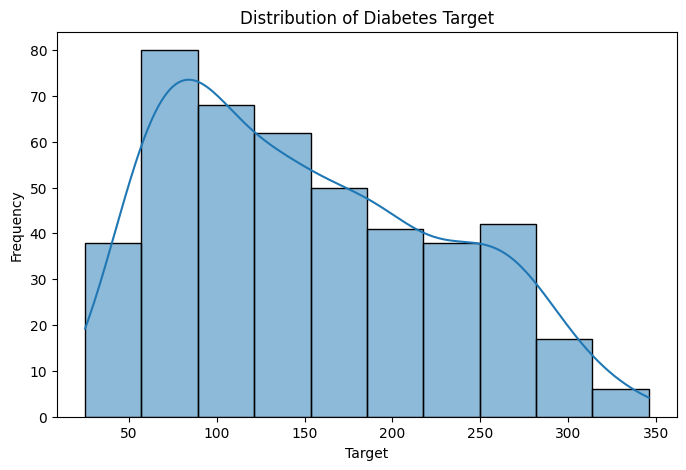

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Target'], kde=True)
plt.title("Distribution of Diabetes Target")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.show()

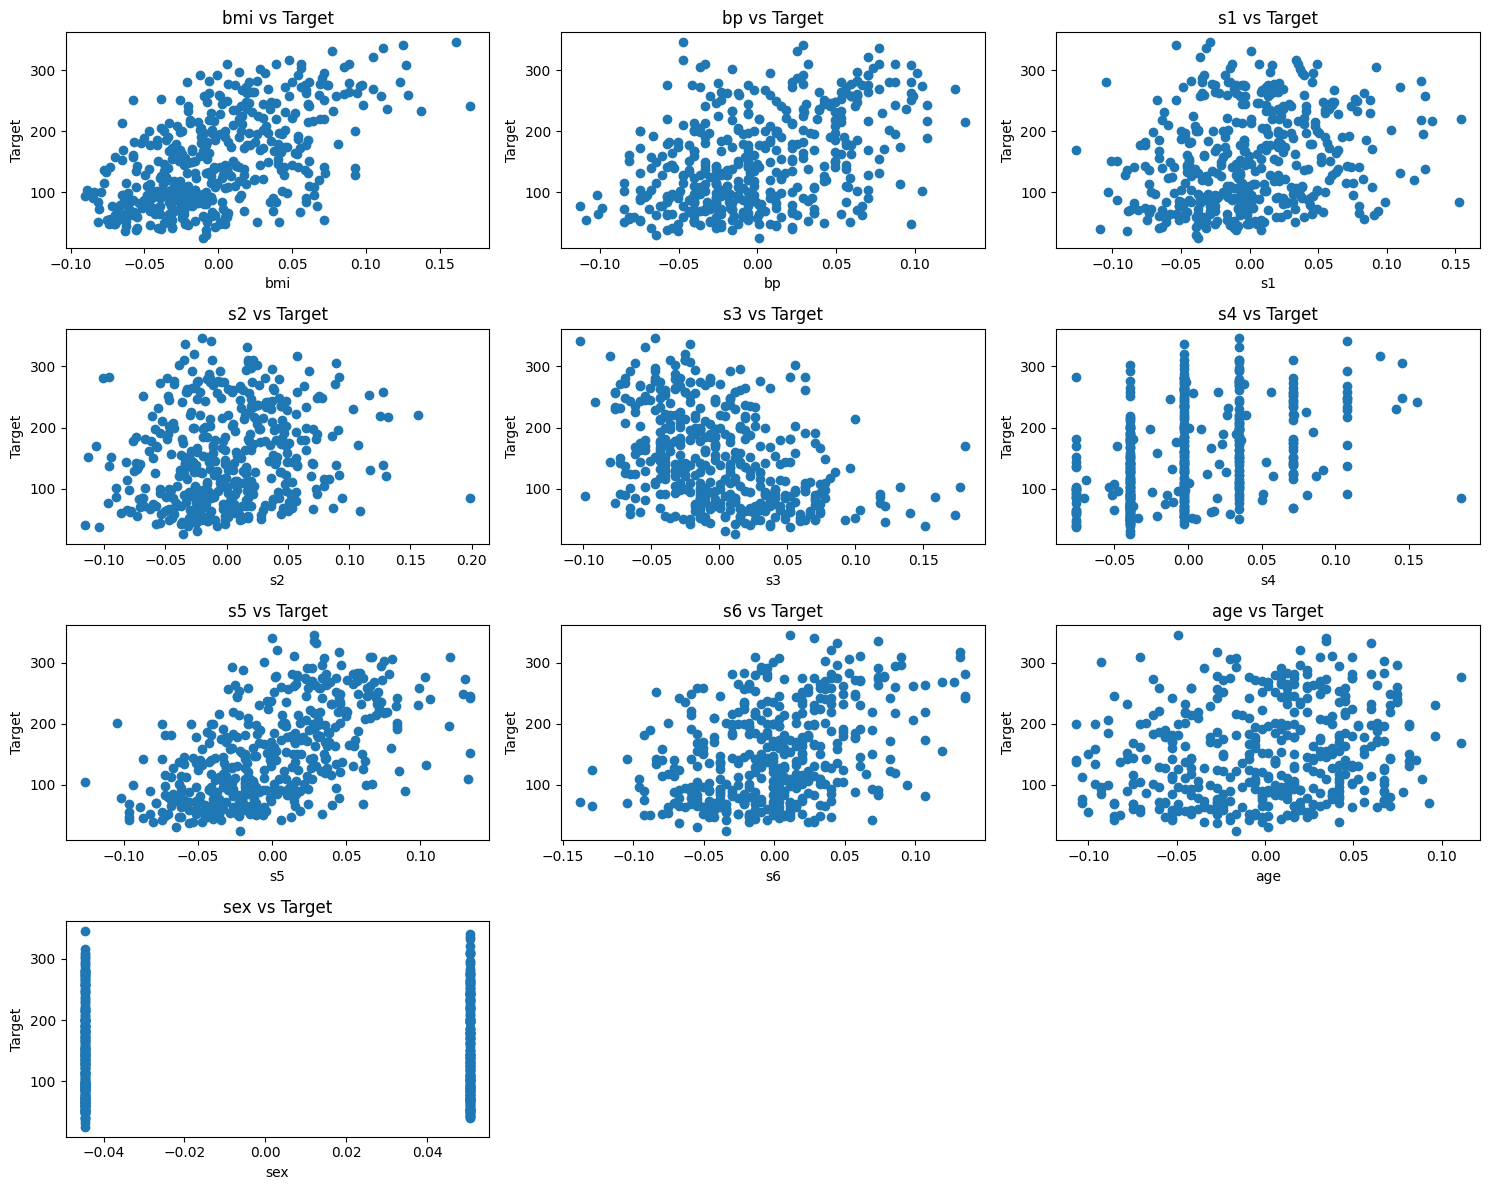

In [11]:
features = ['bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'age', 'sex']

plt.figure(figsize=(15, 12))

for i, feature in enumerate(features):
    plt.subplot(4, 3, i + 1)
    plt.scatter(df[feature], df['Target'])
    plt.xlabel(feature)
    plt.ylabel("Target")
    plt.title(feature + " vs Target")

plt.tight_layout()
plt.show()

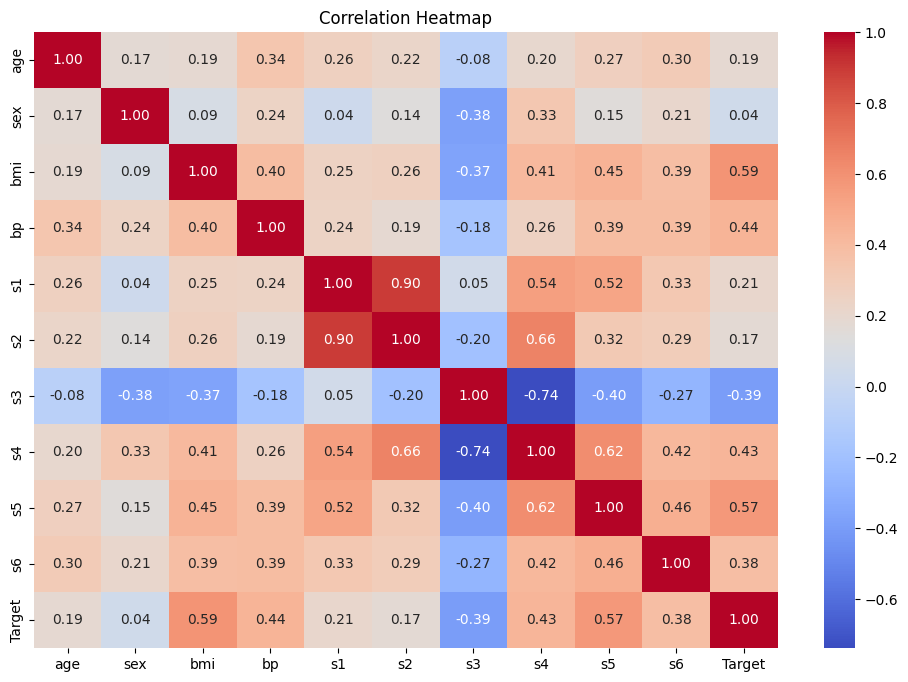

Correlation with Target:
Target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: Target, dtype: float64


In [12]:
correlation = df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with Target:")
print(correlation['Target'].sort_values(ascending=False))

In [13]:
sample = df[['bmi', 'bp', 'Target']].head(8)

X_manual = np.column_stack((
    np.ones(len(sample)),
    sample['bmi'],
    sample['bp']
))

y_manual = sample['Target'].values

print("Sample Data:")
display(sample)

print("\nDesign Matrix X:")
print(X_manual)

print("\nTarget Matrix y:")
print(y_manual)

XTX = X_manual.T @ X_manual
XTy = X_manual.T @ y_manual

print("\nX Transpose X:")
print(XTX)

print("\nX Transpose y:")
print(XTy)

coefficients_manual = np.linalg.solve(XTX, XTy)

print("\nManual Coefficients:")
print("b0 =", coefficients_manual[0])
print("b1 =", coefficients_manual[1])
print("b2 =", coefficients_manual[2])

print("\nManual Regression Equation:")
print(f"Target = {coefficients_manual[0]:.4f} + ({coefficients_manual[1]:.4f} × bmi) + ({coefficients_manual[2]:.4f} × bp)")

Sample Data:


,bmi,bp,Target
0,0.061696,0.021872,151.0
1,-0.051474,-0.026328,75.0
2,0.044451,-0.005670,141.0
3,-0.011595,-0.036656,206.0
4,-0.036385,0.021872,135.0
5,-0.040696,-0.019442,97.0
6,-0.047163,-0.015999,138.0
7,-0.001895,0.066629,63.0



Design Matrix X:
[[ 1.          0.06169621  0.02187239]
 [ 1.         -0.05147406 -0.02632753]
 [ 1.          0.04445121 -0.00567042]
 [ 1.         -0.01159501 -0.03665608]
 [ 1.         -0.03638469  0.02187239]
 [ 1.         -0.04069594 -0.01944183]
 [ 1.         -0.04716281 -0.01599898]
 [ 1.         -0.00189471  0.06662945]]

Target Matrix y:
[151.  75. 141. 206. 135.  97. 138.  63.]

X Transpose X:
[[ 8.00000000e+00 -8.30598074e-02  6.27938630e-03]
 [-8.30598074e-02  1.37742818e-02  3.50129551e-03]
 [ 6.27938630e-03  3.50129551e-03  8.09919838e-03]]

X Transpose y:
[1006.           -6.15265365   -3.96580508]

Manual Coefficients:
b0 = 132.25382734236106
b1 = 563.2452218723266
b2 = -835.6834342078985

Manual Regression Equation:
Target = 132.2538 + (563.2452 × bmi) + (-835.6834 × bp)


In [14]:
manual_model = LinearRegression()

manual_model.fit(sample[['bmi', 'bp']], sample['Target'])

print("Library Intercept:", manual_model.intercept_)
print("Library Coefficients:", manual_model.coef_)

print("\nManual Coefficients:")
print(coefficients_manual)

Library Intercept: 132.25382734236106
Library Coefficients: [ 563.24522187 -835.68343421]

Manual Coefficients:
[ 132.25382734  563.24522187 -835.68343421]


In [15]:
actual_value = y_manual[0]

predicted_value = (
    coefficients_manual[0]
    + coefficients_manual[1] * sample['bmi'].iloc[0]
    + coefficients_manual[2] * sample['bp'].iloc[0]
)

residual = actual_value - predicted_value

print("Actual Value:", actual_value)
print("Predicted Value:", predicted_value)
print("Residual:", residual)

Actual Value: 151.0
Predicted Value: 148.7255306309684
Residual: 2.274469369031607


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 353
Testing Records: 89


In [17]:
train_data = X_train.copy()
train_data['Target'] = y_train

correlations = train_data.corr()['Target'].drop('Target')

best_feature = correlations.abs().idxmax()

print("Selected Feature:", best_feature)
print("Correlation with Target:", correlations[best_feature])

Selected Feature: bmi
Correlation with Target: 0.6047512938220249


In [18]:
single_model = LinearRegression()

single_model.fit(X_train[[best_feature]], y_train)

single_predictions = single_model.predict(X_test[[best_feature]])

print("Single Feature Model")
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Test R2 Score:", r2_score(y_test, single_predictions))

Single Feature Model
Intercept: 152.00335421448167
Coefficient: 998.5776891375606
Test R2 Score: 0.23335039815872138


In [19]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

print("Multiple Feature Model")
print("Intercept:", multiple_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coefficient)

print("\nTest R2 Score:", r2_score(y_test, multiple_predictions))

Multiple Feature Model
Intercept: 151.34560453985995

Coefficients:
age : 37.904021350074636
sex : -241.96436231274015
bmi : 542.4287585162909
bp : 347.7038439138564
s1 : -931.4888458835236
s2 : 518.0622769833429
s3 : 163.41998299131367
s4 : 275.3179015786495
s5 : 736.1988589046866
s6 : 48.670657431965296

Test R2 Score: 0.45260276297191926


In [20]:
equation = f"Target = {multiple_model.intercept_:.4f}"

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    equation += f" + ({coefficient:.4f} × {feature})"

print("Multiple Linear Regression Equation:")
print(equation)

Multiple Linear Regression Equation:
Target = 151.3456 + (37.9040 × age) + (-241.9644 × sex) + (542.4288 × bmi) + (347.7038 × bp) + (-931.4888 × s1) + (518.0623 × s2) + (163.4200 × s3) + (275.3179 × s4) + (736.1989 × s5) + (48.6707 × s6)


In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

print("Standardised Coefficients:")

for feature, coefficient in zip(X.columns, scaled_model.coef_):
    print(feature, ":", coefficient)

Standardised Coefficients:
age : 1.753757991941763
sex : -11.511809081546648
bmi : 25.607121438997417
bp : 16.82887166625278
s1 : -44.448855642536415
s2 : 24.640953560447898
s3 : 7.676977684866896
s4 : 13.138783899963531
s5 : 35.161195210920845
s6 : 2.3513636510244407


In [24]:
comparison = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': multiple_predictions
})

display(comparison.head(15))

,Actual Values,Predicted Values
0,219.0,139.547558
1,70.0,179.517208
2,202.0,134.038756
3,230.0,291.417029
4,111.0,123.789659
5,84.0,92.172347
6,242.0,258.232389
7,272.0,181.337321
8,94.0,90.224113
9,96.0,108.633759


In [25]:
mae = mean_absolute_error(y_test, multiple_predictions)
mse = mean_squared_error(y_test, multiple_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, multiple_predictions)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("Multiple Linear Regression Evaluation")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Adjusted R2 Score:", adjusted_r2)

Multiple Linear Regression Evaluation
MAE: 42.79409467959996
MSE: 2900.1936284934827
RMSE: 53.85344583676594
R2 Score: 0.45260276297191926
Adjusted R2 Score: 0.3824236300196012


In [26]:
single_mae = mean_absolute_error(y_test, single_predictions)
single_mse = mean_squared_error(y_test, single_predictions)
single_rmse = np.sqrt(single_mse)
single_r2 = r2_score(y_test, single_predictions)

results = pd.DataFrame({
    'Model': ['Single Feature', 'Multiple Features'],
    'MAE': [single_mae, mae],
    'MSE': [single_mse, mse],
    'RMSE': [single_rmse, rmse],
    'R2 Score': [single_r2, r2]
})

display(results)

,Model,MAE,MSE,RMSE,R2 Score
0,Single Feature,52.259976,4061.825928,63.732456,0.233350
1,Multiple Features,42.794095,2900.193628,53.853446,0.452603


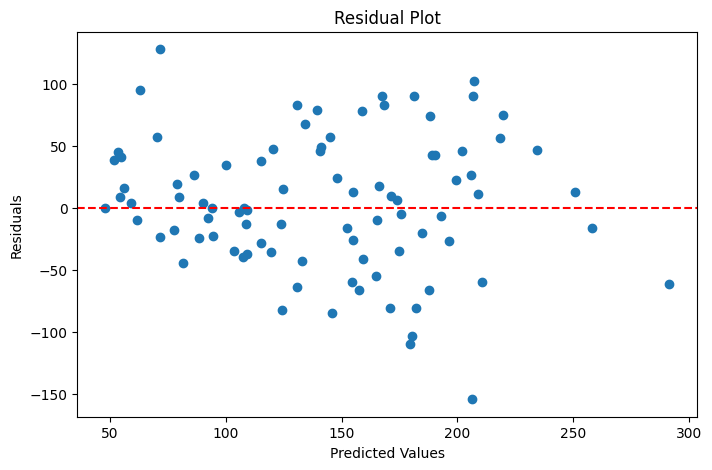

In [27]:
residuals = y_test - multiple_predictions

plt.figure(figsize=(8, 5))
plt.scatter(multiple_predictions, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

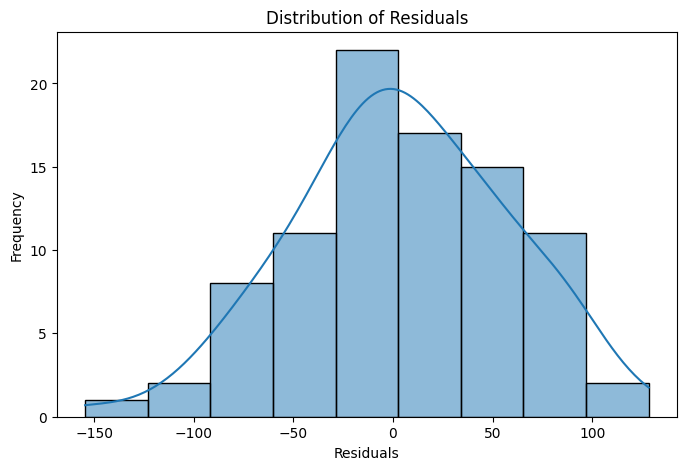

In [28]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

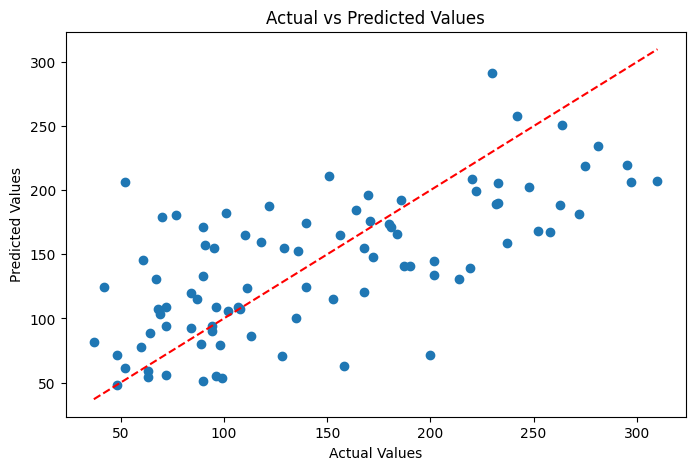

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, multiple_predictions)

minimum = min(y_test.min(), multiple_predictions.min())
maximum = max(y_test.max(), multiple_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.show()

In [30]:
vif_data = pd.DataFrame()

vif_data['Feature'] = X_train.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

display(vif_data)

,Feature,VIF
0,age,1.217114
1,sex,1.268854
2,bmi,1.573561
3,bp,1.422084
4,s1,55.252137
5,s2,35.759309
6,s3,14.285594
7,s4,9.333044
8,s5,10.071155
9,s6,1.500654


In [31]:
new_data = pd.DataFrame([X_train.median()], columns=X.columns)

new_prediction = multiple_model.predict(new_data)

print("New Input Data:")
display(new_data)

print("Predicted Diabetes Target:", new_prediction[0])

New Input Data:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.009016,-0.044642,-0.005128,-0.00567,-0.004321,-0.004132,-0.006584,-0.002592,-0.000612,0.003064


Predicted Diabetes Target: 157.5288900837159


In [32]:
print("CONCLUSION")

print("Multiple Linear Regression was applied to the Diabetes dataset.")
print("The dataset contains numerical input features and a continuous target variable.")
print("The model was evaluated using MAE, MSE, RMSE, R2 and Adjusted R2.")

print("\nSingle Feature R2 Score:", single_r2)
print("Multiple Feature R2 Score:", r2)

if r2 > single_r2:
    print("The multiple-feature model performed better on the test data.")
else:
    print("The single-feature model performed better or equally on the test data.")

print("\nThe model provides estimates and does not guarantee exact predictions.")

CONCLUSION
Multiple Linear Regression was applied to the Diabetes dataset.
The dataset contains numerical input features and a continuous target variable.
The model was evaluated using MAE, MSE, RMSE, R2 and Adjusted R2.

Single Feature R2 Score: 0.23335039815872138
Multiple Feature R2 Score: 0.45260276297191926
The multiple-feature model performed better on the test data.

The model provides estimates and does not guarantee exact predictions.
